# 4.4 — Monte Carlo integration (II): Metropolis

The Metropolis algorithm and the analysis are written out in this notebook;
`functions.py` only holds the plotting helpers.

In [ ]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from functions import *

In [ ]:
# Parameters (quote these in the report captions)
SEED = 1
H_LIST = [1, 0.1]                     # step sizes h of the uniform proposal W_h
STARTS = {"(0, 0, 0)": [0, 0, 0], "(10, 10, 10)": [10, 10, 10]}
N_TRAJ = 10_000                       # (a) steps per trajectory
N_LONG = 1_000_000                    # (a, b) kept steps of the long runs (start at the origin)
N_DISCARD = 20_000                    # (a, b, d) equilibration steps thrown away (> N_eq from (c))
BLOCK_SIZES = 2**np.arange(15)        # (b) block sizes B = 1 ... 16384 for the blocking analysis
B_ERR = 2**13                         # (b, d) block size used for the error bar (on the plateau)
N_CHAINS = 100                        # (c) independent chains started at (10, 10, 10)
N_EQ_STEPS = 20_000                   # (c) steps per chain
H_SCAN = [0.1, 0.2, 0.5, 1, 2, 3, 5, 10, 20]   # (d) step sizes for the scan
N_SCAN = 500_000                      # (d) kept steps per h

NORM = (2 * np.pi)**1.5               # integral of exp(-r^2/2) over R^3
I_EXACT = 3 * NORM                    # analytical result of 4.3 (a)
I_GAUSS, I_GAUSS_ERR = 47.241, 0.067  # 4.3 (b): direct Gaussian sampling, N = 10^6, seed 1

rng = np.random.default_rng(SEED)
set_plot_style()

## The Metropolis algorithm

One step from the current point $\mathbf r$:

1. propose $\mathbf r' = \mathbf r + \boldsymbol\delta$, with $\delta_x, \delta_y, \delta_z$ uniform in $[-h/2, h/2]$ (selection $g$, symmetric);
2. accept with probability $A = \min\!\left(1, e^{-(r'^2 - r^2)/2}\right)$: draw $u$ uniform in $[0, 1)$ and accept if $u < e^{-(r'^2-r^2)/2}$
   (if $r'^2 < r^2$ the exponential is $> 1$, so the move is always accepted);
3. if rejected, the chain stays at $\mathbf r$, and the old point is counted again.

The function runs several independent chains side by side (one row of `r` per chain), so (c) can average over many chains
with the same code. With one chain, `r0 = [[x, y, z]]`.

In [ ]:
def metropolis(r0, h, n_steps, rng):
    """Metropolis chains for w(r) ~ exp(-r^2/2).

    r0: starting points, shape (n_chains, 3). Returns the points after every step,
    shape (n_steps, n_chains, 3), and the acceptance rate.
    """
    r = np.array(r0, dtype=float)                 # current point of every chain
    r2 = np.sum(r**2, axis=1)                     # current r^2 of every chain
    chain = np.empty((n_steps,) + r.shape)
    n_accepted = 0
    for t in range(n_steps):
        r_new = r + rng.uniform(-h / 2, h / 2, size=r.shape)      # proposal r' = r + delta
        r2_new = np.sum(r_new**2, axis=1)
        accept = rng.random(len(r)) < np.exp(-(r2_new - r2) / 2)  # u < w(r') / w(r)
        r[accept] = r_new[accept]                                 # rejected chains keep their old point
        r2[accept] = r2_new[accept]
        n_accepted += np.sum(accept)
        chain[t] = r
    return chain, n_accepted / (n_steps * len(r))


def blocking_error(f, B):
    """Standard error of the mean of the correlated series f, from blocks of B consecutive values.

    Block means of blocks much longer than the correlation time are independent, so their spread
    gives an honest error bar. B = 1 is the naive error s_f / sqrt(N).
    """
    n_blocks = len(f) // B
    block_means = f[:n_blocks * B].reshape(n_blocks, B).mean(axis=1)
    return block_means.std(ddof=1) / np.sqrt(n_blocks)

## (a) Plot the $(x, y)$ trajectory for $N = 10^4$ steps starting at $\mathbf r = (0,0,0)$ and at $\mathbf r = (10,10,10)$, for $h = 1$ and $h = 0.1$. With a run of $N = 10^6$ points, verify via histograms that the equilibrium distribution is $\propto e^{-r^2/2}$.

start    (0, 0, 0), h =   1: acceptance = 0.813, end point = [ 1.21  1.36 -0.34]
start    (0, 0, 0), h = 0.1: acceptance = 0.985, end point = [-0.77 -0.62  0.73]


start (10, 10, 10), h =   1: acceptance = 0.810, end point = [0.37 0.6  0.59]
start (10, 10, 10), h = 0.1: acceptance = 0.941, end point = [1.98 1.62 0.96]


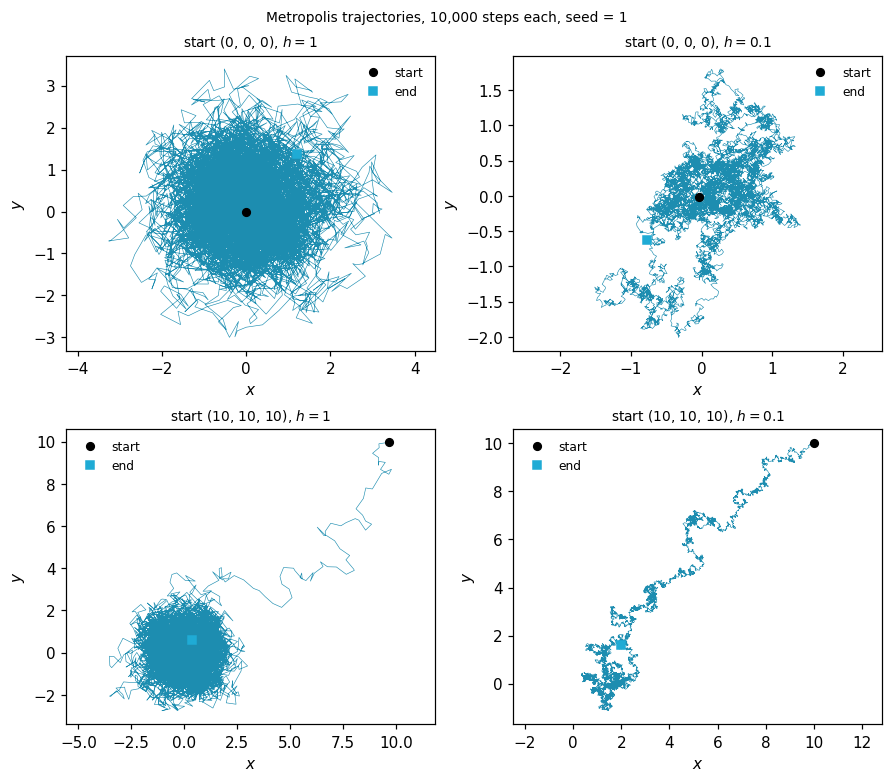

In [ ]:
runs = {}
for start, r0 in STARTS.items():
    for h in H_LIST:
        chain, acc = metropolis([r0], h, N_TRAJ, rng)
        runs[(start, h)] = chain[:, 0]           # the single chain, shape (N_TRAJ, 3)
        print(f"start {start:>12}, h = {h:>3}: acceptance = {acc:.3f}, end point = {np.round(chain[-1, 0], 2)}")

fig = plot_trajectories(runs, title=f"Metropolis trajectories, {N_TRAJ:,} steps each, seed = {SEED}")
save_figure(fig, "trajectories")

h =   1: acceptance = 0.810,  <x>, <y>, <z> = [-0.014  0.01  -0.005],  <x^2>, <y^2>, <z^2> = [1.002 1.    1.001]   (exact 0 and 1)


h = 0.1: acceptance = 0.981,  <x>, <y>, <z> = [-0.063 -0.019  0.061],  <x^2>, <y^2>, <z^2> = [1.023 0.964 1.025]   (exact 0 and 1)


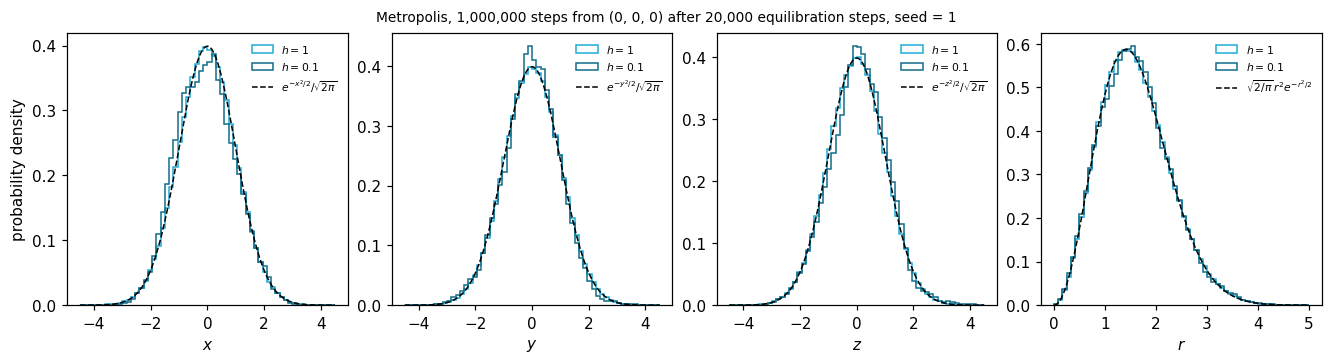

In [ ]:
# long runs from the origin; the first N_DISCARD steps are thrown away
long_runs = {}
for h in H_LIST:
    chain, acc = metropolis([[0, 0, 0]], h, N_DISCARD + N_LONG, rng)
    long_runs[h] = chain[N_DISCARD:, 0]
    x = long_runs[h]
    print(f"h = {h:>3}: acceptance = {acc:.3f},  <x>, <y>, <z> = {np.round(x.mean(axis=0), 3)},"
          f"  <x^2>, <y^2>, <z^2> = {np.round((x**2).mean(axis=0), 3)}   (exact 0 and 1)")

fig = plot_histograms(long_runs, title=f"Metropolis, {N_LONG:,} steps from (0, 0, 0) after {N_DISCARD:,} "
                                       f"equilibration steps, seed = {SEED}")
save_figure(fig, "histograms")

## (b) Estimate the integral with Metropolis and compare with [4.3](../4.03-mc-integration-1/).

As in 4.3, $I = (2\pi)^{3/2}\langle (x+y+z)^2\rangle_w$, but now the average is over the points of the chain.
Successive points are correlated, so $s_f/\sqrt N$ underestimates the error. Blocking: cut the chain into blocks of
$B$ steps and use the spread of the block means. The error grows with $B$ and reaches a plateau once $B \gg \tau$.
The ratio to the naive error gives the integrated autocorrelation time, $(\text{err}_B/\text{err}_1)^2 = 2\tau_\text{int}$.

h =   1: I_MC = 47.637 ± 0.419  (naive error 0.067, tau_int = 19 ± 2 steps),  (I_MC - I_exact) / err = +0.93
h = 0.1: I_MC = 43.473 ± 2.329  (naive error 0.059, tau_int = 768 ± 99 steps),  (I_MC - I_exact) / err = -1.62
exact:          I = 47.249
4.3, Gaussian:  I = 47.241 ± 0.067  (also N = 10^6 points)


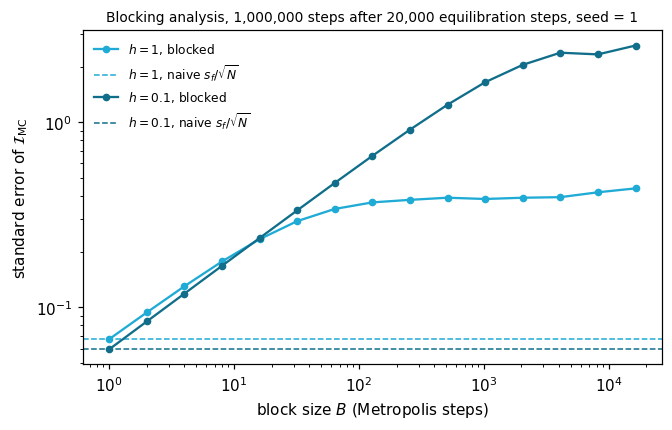

In [ ]:
errors, naive = {}, {}
for h, x in long_runs.items():
    f = NORM * x.sum(axis=1)**2                   # (2 pi)^{3/2} (x+y+z)^2 at every point of the chain
    errors[h] = [blocking_error(f, B) for B in BLOCK_SIZES]
    naive[h] = blocking_error(f, 1)
    err = blocking_error(f, B_ERR)
    n_blocks = N_LONG // B_ERR
    tau = 0.5 * (err / naive[h])**2
    tau_err = tau * np.sqrt(2 / (n_blocks - 1))   # the blocked error is itself uncertain
    print(f"h = {h:>3}: I_MC = {f.mean():.3f} ± {err:.3f}  (naive error {naive[h]:.3f}, tau_int = {tau:.0f} ± {tau_err:.0f} steps),"
          f"  (I_MC - I_exact) / err = {(f.mean() - I_EXACT) / err:+.2f}")
print(f"exact:          I = {I_EXACT:.3f}")
print(f"4.3, Gaussian:  I = {I_GAUSS:.3f} ± {I_GAUSS_ERR:.3f}  (also N = 10^6 points)")

fig = plot_blocking(BLOCK_SIZES, errors, naive,
                    title=f"Blocking analysis, {N_LONG:,} steps after {N_DISCARD:,} equilibration steps, seed = {SEED}")
save_figure(fig, "blocking")

## (c) Estimate the equilibration time $N_{eq}$ starting from $(10,10,10)$ for $h = 1$ and $h = 0.1$.

$r^2$ is a good indicator: it starts at 300 and has to come down to $\langle r^2\rangle = 3$.
One chain is noisy, so we average $r^2(t)$ over `N_CHAINS` independent chains.
In equilibrium $r^2 \sim \chi^2_3$, with variance 6, so the average over the chains fluctuates by $\sqrt{6/N_\text{chains}}$.
$N_{eq}$ = first step at which the average drops below $3 + 2\sqrt{6/N_\text{chains}}$, i.e. it can no longer be told apart from equilibrium.

Rough estimate for small $h$: a Metropolis step drifts by $\frac{\sigma^2}{2}\nabla\ln w = -\frac{h^2}{24}\mathbf r$
($\sigma^2 = h^2/12$ is the variance of one component of $\boldsymbol\delta$), so $\langle r^2\rangle - 3 \approx 297\,e^{-h^2 t/12}$.

h =   1: N_eq =   205   (small-h estimate 77),  acceptance = 0.809


h = 0.1: N_eq =  8485   (small-h estimate 7689),  acceptance = 0.963


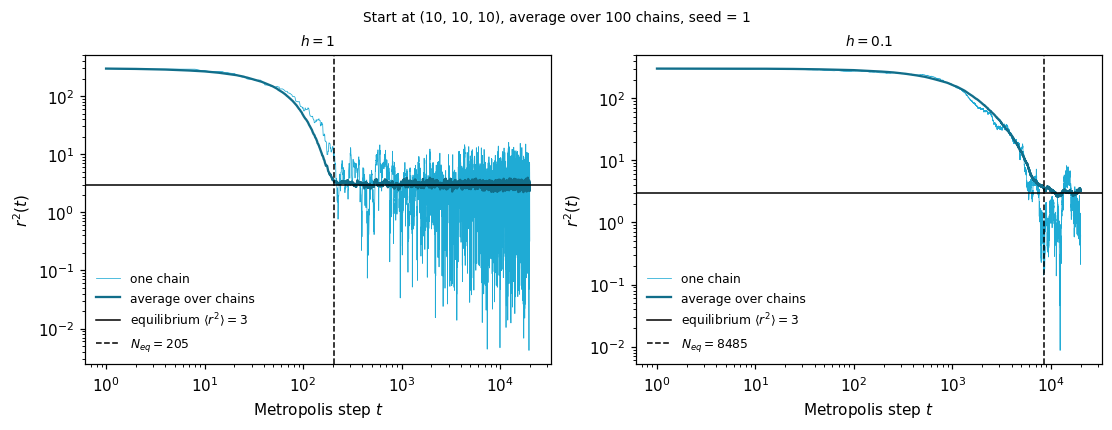

In [ ]:
threshold = 3 + 2 * np.sqrt(6 / N_CHAINS)
r2_mean, r2_single, n_eq = {}, {}, {}
for h in H_LIST:
    chains, acc = metropolis(np.full((N_CHAINS, 3), 10.0), h, N_EQ_STEPS, rng)
    r2 = np.sum(chains**2, axis=2)                # r^2(t) of every chain, shape (N_EQ_STEPS, N_CHAINS)
    r2_mean[h] = r2.mean(axis=1)
    r2_single[h] = r2[:, 0]
    n_eq[h] = np.argmax(r2_mean[h] < threshold) + 1      # chain[t] is the point after t + 1 steps
    estimate = 12 / h**2 * np.log(297 / (threshold - 3))
    print(f"h = {h:>3}: N_eq = {n_eq[h]:>5}   (small-h estimate {estimate:.0f}),  acceptance = {acc:.3f}")

fig = plot_equilibration(r2_mean, r2_single, n_eq,
                         title=f"Start at (10, 10, 10), average over {N_CHAINS} chains, seed = {SEED}")
save_figure(fig, "equilibration")

## (d) Which algorithm do you expect to be better for this calculation: direct Gaussian sampling or Metropolis? Why?

Scan of the step size $h$: acceptance rate and $\tau_\text{int}$ of $f = (x+y+z)^2$ (from blocking, as in (b)).
A chain of $N$ steps is worth $N/(2\tau_\text{int})$ independent points; direct Gaussian sampling has $\tau_\text{int} = 1/2$.

h =  0.1: acceptance = 0.981,  tau_int =  1041.2,  independent points per step = 0.0005


h =  0.2: acceptance = 0.962,  tau_int =   317.4,  independent points per step = 0.0016


h =  0.5: acceptance = 0.904,  tau_int =    68.7,  independent points per step = 0.0073


h =    1: acceptance = 0.811,  tau_int =    18.5,  independent points per step = 0.0271


h =    2: acceptance = 0.634,  tau_int =     5.5,  independent points per step = 0.0914


h =    3: acceptance = 0.480,  tau_int =     5.1,  independent points per step = 0.0989


h =    5: acceptance = 0.256,  tau_int =     4.6,  independent points per step = 0.1094


h =   10: acceptance = 0.053,  tau_int =    15.0,  independent points per step = 0.0334


h =   20: acceptance = 0.006,  tau_int =   146.9,  independent points per step = 0.0034


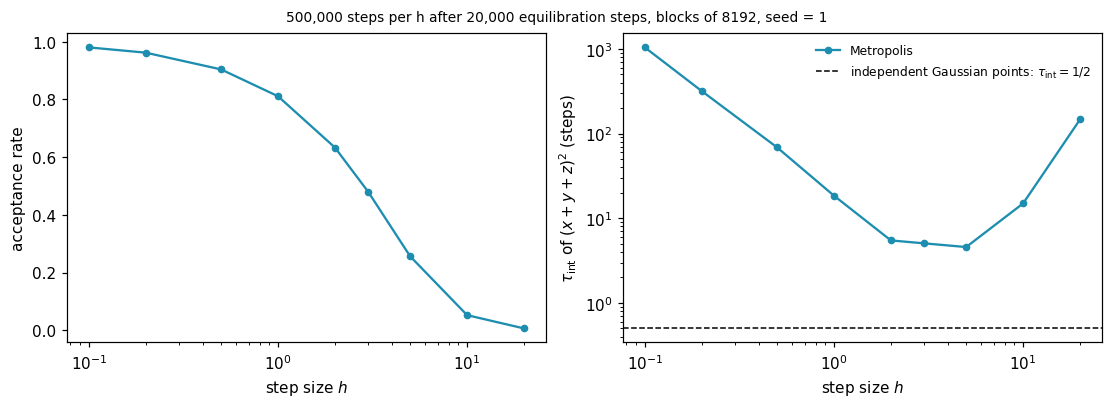

In [ ]:
acc_scan, tau_scan = [], []
for h in H_SCAN:
    chain, acc = metropolis([[0, 0, 0]], h, N_DISCARD + N_SCAN, rng)
    f = NORM * chain[N_DISCARD:, 0].sum(axis=1)**2
    tau = 0.5 * (blocking_error(f, B_ERR) / blocking_error(f, 1))**2
    acc_scan.append(acc)
    tau_scan.append(tau)
    print(f"h = {h:>4}: acceptance = {acc:.3f},  tau_int = {tau:7.1f},  independent points per step = {1 / (2 * tau):.4f}")

fig = plot_h_scan(H_SCAN, acc_scan, tau_scan,
                  title=f"{N_SCAN:,} steps per h after {N_DISCARD:,} equilibration steps, blocks of {B_ERR}, seed = {SEED}")
save_figure(fig, "h_scan")

**Answer.** Direct Gaussian sampling is better here. It gives independent points, so the error is $s_f/\sqrt N$.
A Metropolis step costs about the same (4 random numbers and an exponential), but the points are correlated:
at the best $h$ the chain still needs $2\tau_\text{int}$ steps per independent point, it needs an equilibration period,
and the error bar needs a blocking analysis. Metropolis is worth it when $w$ cannot be sampled directly,
for example a Boltzmann weight of many coupled degrees of freedom (Ising model), or when the normalisation of $w$ is unknown:
only the ratio $w(\mathbf r')/w(\mathbf r)$ enters the acceptance.